# Evaluación, optimización y selección del modelo de recomendación

**Autor:** Lookwise Data Lab
**Proyecto:** Sistema de recomendación para el e-commerce de H&M
**Notebook 06** · Continúa `03_baseline.ipynb`, `04_pipeline_modelos.ipynb` y `05_simulacion_cold_start.ipynb`

---

## Objetivo

Seleccionar, con evidencia, el modelo que H&M debería usar para recomendar 12 prendas a cada cliente. Para eso, el notebook:

1. Define las métricas de evaluación y justifica cuál decide.
2. Optimiza el baseline antes de compararlo, para que la comparación sea exigente.
3. Entrena y compara modelos supervisados (regresión logística y Gradient Boosting) y uno no supervisado (co-compra).
4. Optimiza hiperparámetros y prueba si la mejora del modelo más complejo es significativa.
5. Evalúa el modelo elegido una sola vez en un período nunca visto.
6. Explica qué variables usa el modelo, muestra ejemplos de recomendaciones y documenta limitaciones.

## Modelos evaluados

| Tipo | Modelo | Cómo aprende | Rol en el sistema |
|---|---|---|---|
| Referencia sin aprendizaje | Popularidad (lo más vendido, con ventana o decaimiento temporal) | Regla: cuenta ventas recientes | Vara a superar y recomendación para clientes nuevos |
| No supervisado | Co-compra + recompra (filtrado colaborativo ítem-ítem) | Pares de prendas compradas juntas, sin etiquetas | Modelo independiente y fuente de candidatas y variables del ranker |
| Supervisado | Ranker con regresión logística | Etiqueta compra / no compra de cada par cliente–prenda | Modelo base supervisado |
| Supervisado | Ranker con Gradient Boosting | Etiqueta compra / no compra de cada par cliente–prenda | **Modelo seleccionado** para clientes con historial |

## Estructura

| Sección | Contenido |
|---|---|
| 1 | Datos y protocolo de validación |
| 2 | Métricas de evaluación |
| 3 | Referencia sin aprendizaje: baseline optimizado |
| 4 | Modelo supervisado: ranker con regresión logística |
| 5 | Modelo supervisado: optimización de hiperparámetros |
| 6 | Modelo supervisado: selección entre regresión logística y Gradient Boosting |
| 7 | Modelo no supervisado: co-compra + recompra |
| 8 | Evaluación final en test |
| 9 | Importancia de las variables |
| 10 | Ejemplos de recomendaciones |
| 11 | Justificación del modelo elegido y alternativas descartadas |
| 12 | Limitaciones, conclusiones y próximos pasos |
| 13 | Persistencia del modelo y exportación de resultados |

**Reproducibilidad:** todas las semillas están fijas (`random_state=42`). La ejecución completa (Restart → Run All) tarda entre 15 y 20 minutos con la muestra p10.

## Configuración

In [1]:
import os, sys, time, json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

sys.path.insert(0, os.path.abspath("../src"))
from datos import cargar, tratar, separar, clientes_frios, CORTE_TEST
from metricas import compras_por_cliente, metricas, detalle_por_cliente, tabla_bonita
from modelos import PopularidadReciente, CoCompraRecompra, RankerSupervisado, SistemaPorEtapas
from optimizacion import (PopularidadDecaimiento, etiquetas, metricas_clasificacion, matriz_confusion, umbral_mejor_f1,
                          recomendador_desde_prob, cobertura_candidatos, crear, buscar, CONFIGS_LOGREG, CONFIGS_HGB)

BASE = "E:/Descargas_Henry/PF_HM/datos/p10"   # carpeta local de la muestra p10 (no se versiona)
FIG_DIR, OUT_DIR, MODEL_DIR = "../reports/figures", "../reports", "../models"
for carpeta in (FIG_DIR, MODEL_DIR):
    os.makedirs(carpeta, exist_ok=True)

AZUL, NARANJA, VERDE, GRIS, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993", "#d64545"
TEXTO2 = "#52514e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#d6d5cf",
                     "axes.labelcolor": TEXTO2, "xtick.color": TEXTO2, "ytick.color": TEXTO2,
                     "axes.grid": True, "axes.grid.axis": "x", "grid.color": "#ecebe6",
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "legend.frameon": False})

def guardar(fig, nombre):
    fig.savefig(f"{FIG_DIR}/{nombre}.png", bbox_inches="tight", facecolor="white")

def bootstrap(dif, n=1000, semilla=42):
    """Media e intervalo de confianza del 95% de una diferencia por cliente (remuestreo de clientes)."""
    rng = np.random.default_rng(semilla)
    medias = dif[rng.integers(0, len(dif), size=(n, len(dif)))].mean(axis=1)
    return dif.mean(), *np.percentile(medias, [2.5, 97.5])

pct = lambda v: f"{v * 100:.2f}%"
print("Configuración lista.")

Configuración lista.


---
# 1. Datos y protocolo de validación

Se aplica el mismo tratamiento de datos del notebook 04 y se separan tres períodos consecutivos que no se superponen:

| Período | Fechas | Uso |
|---|---|---|
| Entrenamiento | hasta el 08/09/2020 | ajustar los modelos |
| Validación | 09/09 al 15/09/2020 | elegir baseline, hiperparámetros y modelo |
| Test | 16/09 al 22/09/2020 | medir el modelo elegido, una sola vez |

**Por qué una partición temporal y no aleatoria:** un recomendador se usa para anticipar compras futuras. Una partición aleatoria mezclaría compras posteriores en el entrenamiento y daría resultados optimistas que no se repetirían en producción.

**Por qué un test que se usa una sola vez:** si el test se usara para elegir, dejaría de medir el desempeño esperado y pasaría a formar parte del ajuste.

In [2]:
trans, cust, art = cargar(BASE)
trans, cust, art, _ = tratar(trans, cust, art)
train, test = separar(trans, CORTE_TEST)
VAL = CORTE_TEST - pd.Timedelta(days=7)
tramo = cust.set_index("customer_id")["tramo_edad"].to_dict()
compras_val = compras_por_cliente(train[train["t_dat"] >= VAL])
compras_test = compras_por_cliente(test)
frios = clientes_frios(trans, CORTE_TEST)
print(f"Clientes con compras en validación: {len(compras_val):,}")
print(f"Clientes con compras en test: {len(compras_test):,} (de ellos, {len(frios & set(compras_test)):,} sin compras previas)")

Clientes con compras en validación: 4,356
Clientes con compras en test: 4,162 (de ellos, 437 sin compras previas)


---
# 2. Métricas de evaluación

El sistema muestra 12 prendas a cada cliente. Se evalúa en dos niveles:

| Nivel | Métrica | Qué responde |
|---|---|---|
| Lista de 12 | **Recall@12** | Qué proporción de lo que el cliente compró estaba entre sus 12 recomendaciones |
| Lista de 12 | Hit Rate@12 | Qué porcentaje de clientes compró al menos una prenda recomendada |
| Lista de 12 | Precision@12 | Qué proporción de las 12 recomendaciones fue comprada |
| Lista de 12 | MAP@12 | Si las prendas compradas aparecen en las primeras posiciones |
| Lista de 12 | Cobertura de catálogo | Cuántas prendas distintas recomienda el sistema |
| Par cliente–prenda | Accuracy, Balanced accuracy | Proporción de predicciones correctas (compra / no compra) |
| Par cliente–prenda | Recall, Precision, F1 | Capacidad de detectar compras y costo en falsas alarmas |
| Par cliente–prenda | ROC-AUC, PR-AUC | Capacidad de ordenar compras por encima de no compras, sin depender de un umbral |

**Métrica de decisión: Recall@12**, con MAP@12 como criterio de desempate. Es la que mejor se vincula con el KPI de negocio (conversión): mide cuántas de las compras reales habrían sido visibles en la vitrina personalizada.

**Relación con los notebooks anteriores:** en los notebooks 03 a 05 la comparación se hizo con MAP@12, que prioriza el orden de la lista. En este notebook se adopta Recall@12 como métrica de decisión porque se vincula de forma más directa con la conversión. La elección del modelo no cambia con el criterio: el ranker supervisado obtiene el mejor resultado tanto en Recall@12 como en MAP@12 (sección 7).

**Por qué la Accuracy no decide:** cada cliente compra muy pocas prendas entre miles posibles, de modo que la clase "compra" es muy minoritaria. Un modelo que nunca predice compra obtiene una Accuracy cercana al 100% sin aportar valor. Se reporta por transparencia y se demuestra el problema en la sección 4.

---
# 3. Referencia sin aprendizaje · Baseline optimizado (popularidad)

**Método:** se comparan 9 variantes de "lo más vendido": ventanas de 1, 3, 7, 14 y 30 días, todo el historial y popularidad con decaimiento temporal (todas las ventas de 60 días, donde una venta pierde la mitad de su peso cada 3, 7 o 14 días). Cada variante se evalúa en **4 semanas consecutivas** (19/08 al 15/09/2020) y se elige la de mayor Recall@12 promedio.

**Por qué optimizar el baseline:** un baseline débil exagera la mejora de cualquier modelo. Compararse contra la mejor versión de la regla simple es una prueba más exigente.

**Por qué 4 semanas:** en moda, la demanda cambia de una semana a otra. Elegir con una sola semana puede premiar una variante que acertó por circunstancias puntuales.

In [3]:
candidatos_base = [PopularidadReciente(d) for d in [1, 3, 7, 14, 30, None]] + [PopularidadDecaimiento(v) for v in [3, 7, 14]]
SEMANAS = [VAL - pd.Timedelta(days=7 * i) for i in range(4)]
compras_semana = {s: compras_por_cliente(train[(train["t_dat"] >= s) & (train["t_dat"] < s + pd.Timedelta(days=7))]) for s in SEMANAS}
filas = []
for m in candidatos_base:
    res = []
    for s in SEMANAS:
        m.fit(train, s)
        res.append(metricas(compras_semana[s], m.recomendar))
    prom = {k: float(np.mean([r[k] for r in res])) for k in res[0]}
    prom["Prendas distintas"] = int(round(prom["Prendas distintas"]))
    filas.append({"Baseline": m.nombre, **prom, "_obj": m})
val_base = pd.DataFrame(filas).sort_values(["Recall@12", "MAP@12"], ascending=False).reset_index(drop=True)
BASELINE_OPT = val_base.loc[0, "_obj"]
original = val_base[val_base["Baseline"] == "Baseline: popularidad 7 días"].iloc[0]
ganador = val_base.iloc[0]
mejor = metricas(compras_val, BASELINE_OPT.fit(train, VAL).recomendar)   # semana de validación, para comparar con los modelos
print(f"Baseline seleccionado: {BASELINE_OPT.nombre}")
print(f"Recall@12 promedio en 4 semanas: {pct(ganador['Recall@12'])} frente a {pct(original['Recall@12'])} "
      f"de la popularidad de 7 días ({(ganador['Recall@12'] / original['Recall@12'] - 1) * 100:+.0f}%)")
tabla_bonita(val_base.drop(columns="_obj"))

Baseline seleccionado: Baseline con decaimiento (vida media 3 días)
Recall@12 promedio en 4 semanas: 2.54% frente a 2.38% de la popularidad de 7 días (+7%)


,Baseline,MAP@12,Prendas distintas,Hit Rate@12 (%),Recall@12 (%),Precision@12 (%)
0,Baseline con decaimiento (vida media 3 días),0.0076,12,7.10,2.54,0.62
1,Baseline con decaimiento (vida media 7 días),0.0075,12,6.92,2.46,0.61
2,Baseline: popularidad 3 días,0.0062,12,6.60,2.41,0.59
3,Baseline: popularidad 7 días,0.0073,12,6.61,2.38,0.58
4,Baseline: popularidad 1 días,0.0061,12,6.47,2.27,0.57
5,Baseline: popularidad 14 días,0.0059,12,6.23,2.19,0.54
6,Baseline con decaimiento (vida media 14 días),0.0064,12,6.08,2.17,0.54
7,Baseline: popularidad 30 días,0.0060,12,5.95,2.02,0.54
8,Baseline: popularidad histórica,0.0049,12,3.21,1.13,0.31


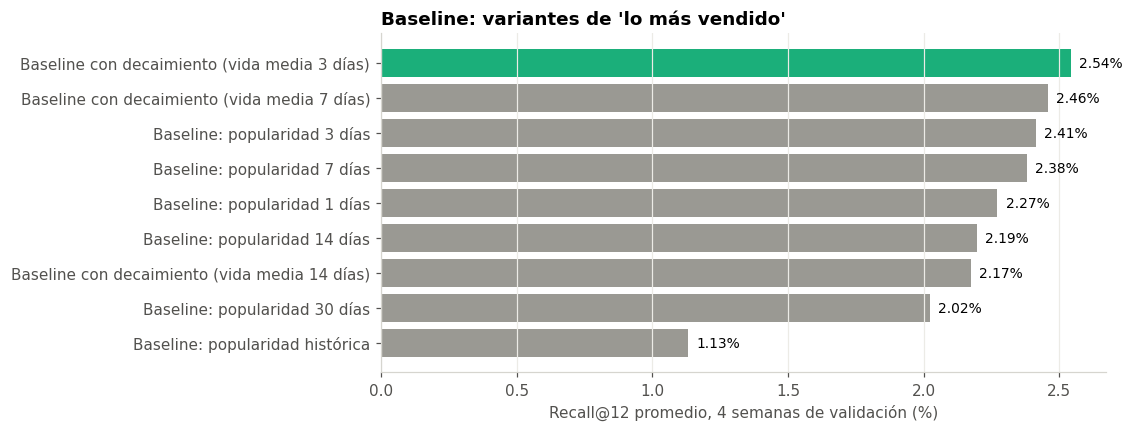

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 4))
d = val_base.iloc[::-1]
colores = [VERDE if n == BASELINE_OPT.nombre else GRIS for n in d["Baseline"]]
ax.barh(d["Baseline"], d["Recall@12"] * 100, color=colores)
for y, v in enumerate(d["Recall@12"] * 100):
    ax.text(v + 0.03, y, f"{v:.2f}%", va="center", fontsize=9)
ax.set_xlabel("Recall@12 promedio, 4 semanas de validación (%)")
ax.set_title("Baseline: variantes de 'lo más vendido'")
guardar(fig, "23_baseline_optimizado")
plt.show()

### Interpretación

- **La recencia es la señal dominante.** Las variantes que priorizan las ventas recientes (decaimiento de 3 y 7 días, ventanas de 3 y 7 días) ocupan los primeros puestos; la popularidad de todo el historial queda última, con menos de la mitad del Recall@12. En moda, lo que se vendió hace meses predice poco lo que se comprará la semana siguiente.
- **Las diferencias entre las mejores variantes son pequeñas** (décimas de punto). Ajustar la regla de popularidad mejora poco: el margen de mejora real está en personalizar.
- **Decisión:** el baseline seleccionado es la referencia que deben superar los modelos y la recomendación para clientes sin historial.

---
# 4. Modelo supervisado · Ranker con regresión logística (modelo base)

**Método:** para cada cliente se genera un conjunto de unas 40 prendas candidatas (populares en general, populares en su tramo de edad y sugeridas por co-compra). Un clasificador estima, para cada par (cliente, prenda), la probabilidad de compra; las 12 candidatas con mayor probabilidad forman la recomendación.

- Entrenamiento: compras del 02/09 al 08/09/2020 como etiqueta, con variables calculadas hasta el 01/09.
- Validación: compras del 09/09 al 15/09/2020.

**Por qué empezar con regresión logística:** es el modelo supervisado más simple, rápido e interpretable. Funciona como modelo base: un algoritmo más complejo solo se justifica si lo supera de forma significativa (sección 6).

In [5]:
t0 = time.time()
ranker_val = RankerSupervisado(tramo, cust, art, dias_pares=28, algoritmo="logreg")
ranker_val.fit(train, VAL, clientes=list(compras_val))
COLS = RankerSupervisado.COLUMNAS
X_tr, y_tr = ranker_val.X_entrenamiento, ranker_val.y_entrenamiento
tabla_val = ranker_val.tabla_prediccion.reset_index(drop=True)
y_val = etiquetas(tabla_val, compras_val)
prob_lr = ranker_val.clf.predict_proba(tabla_val[COLS])[:, 1]
techo = cobertura_candidatos(tabla_val, compras_val)
print(f"Tiempo: {time.time() - t0:,.0f} s")
print(f"Entrenamiento: {len(y_tr):,} pares cliente-prenda, {y_tr.sum():,} compras ({pct(y_tr.mean())})")
print(f"Validación: {len(y_val):,} pares, {y_val.sum():,} compras ({pct(y_val.mean())})")
print(f"Compras de validación incluidas entre las candidatas: {pct(techo)} (límite superior del Recall del ranker)")

Tiempo: 103 s
Entrenamiento: 399,548 pares cliente-prenda, 1,818 compras (0.46%)
Validación: 400,405 pares, 1,802 compras (0.45%)
Compras de validación incluidas entre las candidatas: 11.90% (límite superior del Recall del ranker)


### 4.1 Por qué la Accuracy no alcanza

Se compara la regresión logística con un clasificador trivial que predice siempre "no compra", y con la misma regresión usando el umbral que maximiza F1 en validación.

In [6]:
m_trivial = metricas_clasificacion(y_val, np.zeros_like(prob_lr) + 1e-9)
m_lr = metricas_clasificacion(y_val, prob_lr, 0.5)
U_F1 = umbral_mejor_f1(y_val, prob_lr)
m_lr_f1 = metricas_clasificacion(y_val, prob_lr, U_F1)
comp = pd.DataFrame([{"Modelo": "Siempre 'no compra'", **m_trivial},
                     {"Modelo": "Regresión logística, umbral 0,5", **m_lr},
                     {"Modelo": f"Regresión logística, umbral {U_F1:.3f} (mejor F1)", **m_lr_f1}])
comp.round(4)

,Modelo,Umbral,Accuracy,Balanced accuracy,Recall,Precision,F1,ROC-AUC,PR-AUC
0,Siempre 'no compra',0.5000,0.9955,0.5000,0.0000,0.0000,0.0000,0.5000,0.0045
1,"Regresión logística, umbral 0,5",0.5000,0.9955,0.5008,0.0017,0.6000,0.0033,0.7208,0.0339
2,"Regresión logística, umbral 0.026 (mejor F1)",0.0257,0.9861,0.5850,0.1804,0.0736,0.1045,0.7208,0.0339


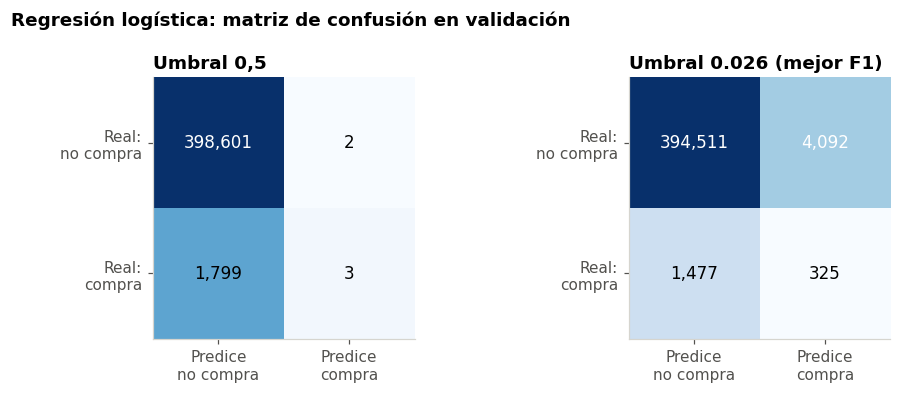

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (titulo, u) in zip(axes, [("Umbral 0,5", 0.5), (f"Umbral {U_F1:.3f} (mejor F1)", U_F1)]):
    m = matriz_confusion(y_val, prob_lr, u)
    ax.imshow(np.log1p(m.values), cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{m.values[i, j]:,}", ha="center", va="center", fontsize=11,
                    color="white" if np.log1p(m.values[i, j]) > np.log1p(m.values).max() * 0.6 else "black")
    ax.set_xticks([0, 1], ["Predice\nno compra", "Predice\ncompra"]); ax.set_yticks([0, 1], ["Real:\nno compra", "Real:\ncompra"])
    ax.grid(False); ax.set_title(titulo)
fig.suptitle("Regresión logística: matriz de confusión en validación", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "24_matriz_confusion")
plt.show()

### Interpretación

- **Desbalance extremo:** solo alrededor del 0,5% de los pares cliente–prenda terminan en compra. Por eso el clasificador trivial alcanza una Accuracy del 99,5% con Recall 0%: no detecta ninguna compra.
- **El umbral de 0,5 no sirve en este problema.** La regresión logística con ese umbral casi nunca predice compra (Recall de 0,2%) y su Accuracy es prácticamente igual a la del modelo trivial.
- **Con el umbral ajustado** (el que maximiza F1), el modelo detecta alrededor del 18% de las compras con una Precision cercana al 7%, unas 16 veces la tasa base de compra. ROC-AUC de 0,72: el modelo ordena las compras por encima de las no compras bastante mejor que el azar (0,5).
- **Implicancia para el recomendador:** no hace falta un umbral. Se ordena por probabilidad y se muestran las 12 primeras, por lo que la métrica que decide es Recall@12. Las métricas de clasificación se reportan como diagnóstico.
- **Límite estructural:** las candidatas contienen cerca del 12% de lo que los clientes compran. Ningún clasificador puede recomendar prendas que no estén entre las candidatas; mejorar la generación de candidatas es la palanca con más potencial.

---
# 5. Modelo supervisado · Optimización de hiperparámetros (regresión logística y Gradient Boosting)

**Método:** búsqueda en grilla de 16 configuraciones, entrenadas y evaluadas con los mismos datos:

| Algoritmo | Hiperparámetros explorados |
|---|---|
| Regresión logística | Regularización `C` ∈ {0,01; 0,1; 1; 10} × `class_weight` ∈ {ninguno, balanceado} |
| Gradient Boosting (HistGradientBoosting) | (tasa de aprendizaje, hojas por árbol, iteraciones) ∈ {(0,05; 15; 200), (0,1; 31; 200), (0,05; 31; 400), (0,1; 63; 300)} × `class_weight`; regularización L2 = 1 |

**Por qué estos hiperparámetros:** `C` y la regularización L2 controlan el sobreajuste; la tasa de aprendizaje, el tamaño de los árboles y las iteraciones controlan la capacidad del Gradient Boosting; `class_weight="balanced"` compensa el desbalance de clases.

**Criterio:** mayor Recall@12 en validación; desempate por MAP@12. Se eligió una grilla acotada en lugar de una búsqueda exhaustiva porque cada configuración requiere reconstruir el ranking de 4.000 clientes, y el objetivo del sprint es la metodología más que el máximo desempeño.

In [8]:
t0 = time.time()
busqueda = pd.concat([buscar(CONFIGS_LOGREG, X_tr, y_tr, tabla_val, y_val, compras_val, metricas, ranker_val._respaldo, COLS),
                      buscar(CONFIGS_HGB, X_tr, y_tr, tabla_val, y_val, compras_val, metricas, ranker_val._respaldo, COLS)],
                     ignore_index=True).sort_values(["Recall@12", "MAP@12"], ascending=False).reset_index(drop=True)
nombre_alg = {"logreg": "Regresión logística", "hgb": "Gradient Boosting"}
mejor_lr = busqueda[busqueda["algoritmo"] == "logreg"].iloc[0]
mejor_hgb = busqueda[busqueda["algoritmo"] == "hgb"].iloc[0]
lr_default = busqueda[(busqueda["algoritmo"] == "logreg") & (busqueda["Configuración"] == "C=1.0, class_weight=None")].iloc[0]
print(f"{len(busqueda)} configuraciones evaluadas en {time.time() - t0:,.0f} s")
print(f"Mejor regresión logística: {mejor_lr['Configuración']} | Recall@12 {pct(mejor_lr['Recall@12'])} "
      f"(configuración por defecto: {pct(lr_default['Recall@12'])})")
print(f"Mejor Gradient Boosting: {mejor_hgb['Configuración']} | Recall@12 {pct(mejor_hgb['Recall@12'])}")
vista = busqueda.drop(columns=["_cfg"]).assign(Algoritmo=lambda d: d["algoritmo"].map(nombre_alg)).drop(columns="algoritmo")
vista[["Algoritmo", "Configuración", "Recall@12", "Hit Rate@12", "MAP@12", "Accuracy", "Recall (clasificador)",
       "Precision (clasificador)", "F1", "PR-AUC", "Segundos"]].round(4)

16 configuraciones evaluadas en 104 s
Mejor regresión logística: C=10.0, class_weight=balanced | Recall@12 6.52% (configuración por defecto: 6.49%)
Mejor Gradient Boosting: learning_rate=0.05, max_leaf_nodes=15, max_iter=200, l2_regularization=1.0, class_weight=balanced | Recall@12 6.92%


,Algoritmo,Configuración,Recall@12,Hit Rate@12,MAP@12,Accuracy,Recall (clasificador),Precision (clasificador),F1,PR-AUC,Segundos
0,Gradient Boosting,"learning_rate=0.05, max_leaf_nodes=15, max_ite...",0.0692,0.1481,0.0339,0.7746,0.5838,0.0116,0.0228,0.0414,8.1
1,Gradient Boosting,"learning_rate=0.05, max_leaf_nodes=31, max_ite...",0.0687,0.1455,0.0334,0.9955,0.0000,0.0000,0.0000,0.0396,11.7
2,Gradient Boosting,"learning_rate=0.05, max_leaf_nodes=15, max_ite...",0.0685,0.1449,0.0330,0.9955,0.0011,1.0000,0.0022,0.0427,11.3
3,Gradient Boosting,"learning_rate=0.1, max_leaf_nodes=31, max_iter...",0.0678,0.1414,0.0321,0.9955,0.0017,0.4286,0.0033,0.0362,8.2
4,Gradient Boosting,"learning_rate=0.1, max_leaf_nodes=31, max_iter...",0.0669,0.1423,0.0322,0.8073,0.5305,0.0124,0.0242,0.0409,6.3
5,Gradient Boosting,"learning_rate=0.05, max_leaf_nodes=31, max_ite...",0.0667,0.1435,0.0330,0.8029,0.5438,0.0124,0.0242,0.0400,9.0
6,Regresión logística,"C=10.0, class_weight=balanced",0.0652,0.1371,0.0318,0.7790,0.5483,0.0111,0.0218,0.0339,4.3
7,Regresión logística,"C=1.0, class_weight=balanced",0.0652,0.1371,0.0317,0.7790,0.5483,0.0111,0.0218,0.0339,5.0
8,Regresión logística,"C=0.1, class_weight=balanced",0.0652,0.1371,0.0317,0.7790,0.5483,0.0111,0.0218,0.0339,3.4
9,Regresión logística,"C=0.01, class_weight=balanced",0.0651,0.1368,0.0316,0.7791,0.5488,0.0112,0.0219,0.0339,4.9


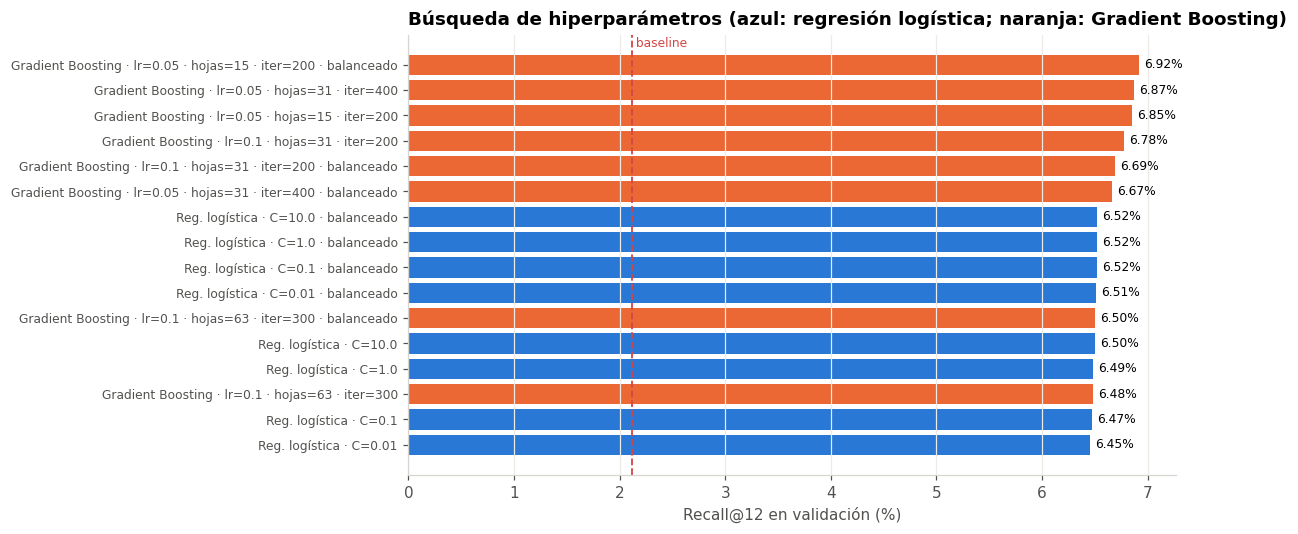

In [9]:
def corto(cfg):
    bal = " · balanceado" if cfg.get("class_weight") == "balanced" else ""
    if cfg["algoritmo"] == "logreg":
        return f"Reg. logística · C={cfg['C']}{bal}"
    return f"Gradient Boosting · lr={cfg['learning_rate']} · hojas={cfg['max_leaf_nodes']} · iter={cfg['max_iter']}{bal}"

fig, ax = plt.subplots(figsize=(9, 5.2))
d = busqueda.iloc[::-1]
colores = [AZUL if a == "logreg" else NARANJA for a in d["algoritmo"]]
ax.barh(range(len(d)), d["Recall@12"] * 100, color=colores)
ax.set_yticks(range(len(d)), [corto(c) for c in d["_cfg"]], fontsize=8)
for y, v in enumerate(d["Recall@12"] * 100):
    ax.text(v + 0.05, y, f"{v:.2f}%", va="center", fontsize=8)
ax.axvline(mejor["Recall@12"] * 100, color=ROJO, ls="--", lw=1.2)
ax.text(mejor["Recall@12"] * 100, len(d) - 0.4, " baseline", color=ROJO, fontsize=8, va="bottom")
ax.set_xlabel("Recall@12 en validación (%)")
ax.set_title("Búsqueda de hiperparámetros (azul: regresión logística; naranja: Gradient Boosting)")
guardar(fig, "25_busqueda_hiperparametros")
plt.show()

### Interpretación

- **Todas las configuraciones superan ampliamente al baseline** (alrededor de 6,5% frente a 2,1% de Recall@12 en validación). La mayor parte de la ganancia proviene de personalizar, no del ajuste fino.
- **En la regresión logística, `C` prácticamente no cambia el resultado** (6,45% a 6,52%): con 17 variables y 400.000 pares, el modelo no está sobreajustando y la regularización tiene poco efecto.
- **`class_weight="balanced"` cambia mucho las métricas de clasificación y poco el Recall@12.** El Recall del clasificador con umbral 0,5 pasa de casi 0% a más del 50%, porque las probabilidades se desplazan hacia arriba; pero el orden de las candidatas casi no cambia, y el ranking es lo que determina las 12 recomendaciones. Esto confirma que las métricas de clasificación a umbral fijo no deben guiar la elección en un recomendador.
- **Gradient Boosting obtiene el mejor Recall@12** con la configuración más regularizada (árboles pequeños, tasa de aprendizaje baja) y clases balanceadas. Las configuraciones más grandes (63 hojas) rinden menos, lo que sugiere sobreajuste.

---
# 6. Modelo supervisado · Selección entre regresión logística y Gradient Boosting

La diferencia de Recall@12 entre la mejor regresión logística y el mejor Gradient Boosting es de pocas décimas. Para decidir si esa diferencia es real o producto del azar, se calcula el Recall@12 de cada cliente con ambos modelos y se estima un intervalo de confianza del 95% de la diferencia mediante bootstrap (1.000 remuestreos de clientes).

**Regla de decisión, fijada antes de ver el resultado:** se elige Gradient Boosting solo si el intervalo no incluye el cero. Si lo incluye, se prefiere la regresión logística por ser más simple, rápida e interpretable.

In [10]:
def recomendador_cfg(cfg):
    clf = crear(cfg).fit(X_tr, y_tr)
    prob = clf.predict_proba(tabla_val[COLS])[:, 1]
    return clf, prob, recomendador_desde_prob(tabla_val, prob, ranker_val._respaldo)

clf_lr_opt, prob_lr_opt, rec_lr = recomendador_cfg(mejor_lr["_cfg"])
clf_gb_opt, prob_gb_opt, rec_gb = recomendador_cfg(mejor_hgb["_cfg"])
r_lr = detalle_por_cliente(compras_val, rec_lr)[0]["recall"].to_numpy()
r_gb = detalle_por_cliente(compras_val, rec_gb)[0]["recall"].to_numpy()
dif_media, dif_bajo, dif_alto = bootstrap(r_gb - r_lr)
gb_significativo = dif_bajo > 0
MEJOR_CFG = mejor_hgb["_cfg"] if gb_significativo else mejor_lr["_cfg"]
clf_mejor, prob_mejor_val = (clf_gb_opt, prob_gb_opt) if gb_significativo else (clf_lr_opt, prob_lr_opt)
U_MEJOR = umbral_mejor_f1(y_val, prob_mejor_val)
print(f"Diferencia de Recall@12 (Gradient Boosting - regresión logística): {dif_media * 100:+.2f} puntos")
print(f"Intervalo del 95%: [{dif_bajo * 100:+.2f}; {dif_alto * 100:+.2f}]")
print(f"Modelo seleccionado: {nombre_alg[MEJOR_CFG['algoritmo']]} "
      + ("(la mejora es significativa)" if gb_significativo else "(la diferencia no es significativa: se prefiere el modelo más simple)"))
print(f"Umbral de mejor F1 del modelo seleccionado, en validación: {U_MEJOR:.3f}")

Diferencia de Recall@12 (Gradient Boosting - regresión logística): +0.40 puntos
Intervalo del 95%: [+0.11; +0.68]
Modelo seleccionado: Gradient Boosting (la mejora es significativa)
Umbral de mejor F1 del modelo seleccionado, en validación: 0.891


### Interpretación

- **La ventaja del Gradient Boosting es pequeña pero real:** +0,40 puntos de Recall@12 sobre la mejor regresión logística, con un intervalo de confianza del 95% entre +0,11 y +0,68 puntos. Como el intervalo no incluye el cero, la regla fijada de antemano selecciona Gradient Boosting.
- **El costo de esa mejora es acotado:** el entrenamiento demora segundos y la pérdida de interpretabilidad se compensa con el análisis de importancia de variables (sección 9).
- **El umbral se recalcula para el modelo seleccionado** (0,891 frente a 0,026 de la regresión logística). Con clases balanceadas, el Gradient Boosting produce probabilidades mucho más altas, por lo que un umbral calibrado para un modelo no es válido para otro.

---
# 7. Modelo no supervisado · Co-compra + recompra (filtrado colaborativo ítem-ítem)

**Método:** filtrado colaborativo ítem-ítem. Sin usar etiquetas, identifica pares de prendas que los mismos clientes compran en un período corto y recomienda las que acompañan a las compras recientes del cliente. Se agrega la recompra (volver a sugerir lo que el cliente ya compró) y se completa con el baseline cuando faltan prendas.

Se prueban ventanas de 14 y 28 días, con y sin recompra.

**Por qué incluirlo:** es la técnica clásica de recomendación y cumple un doble rol: se evalúa como modelo independiente y además aporta candidatas y variables al ranker supervisado.

In [11]:
filas = []
for dp in [14, 28]:
    for w in [0.0, 1.0]:
        m = CoCompraRecompra(BASELINE_OPT, dias_pares=dp, peso_recompra=w).fit(train, VAL)
        filas.append({"Modelo": m.nombre, **metricas(compras_val, m.recomendar), "_obj": m})
val_cc = pd.DataFrame(filas).sort_values(["Recall@12", "MAP@12"], ascending=False).reset_index(drop=True)
COCOMPRA = val_cc.loc[0, "_obj"]
print(f"Mejor variante en validación: {COCOMPRA.nombre} | Recall@12 {pct(val_cc.loc[0, 'Recall@12'])}")
tabla_bonita(val_cc.drop(columns="_obj"))

Mejor variante en validación: Modelo 2: co-compra + recompra (28 días) | Recall@12 6.17%


,Modelo,MAP@12,Prendas distintas,Hit Rate@12 (%),Recall@12 (%),Precision@12 (%)
0,Modelo 2: co-compra + recompra (28 días),0.0305,10561,11.48,6.17,1.24
1,Modelo 2: co-compra + recompra (14 días),0.0302,10410,11.62,6.06,1.23
2,Modelo 2: co-compra (28 días),0.0200,6813,8.79,4.32,0.93
3,Modelo 2: co-compra (14 días),0.0190,5347,8.98,4.17,0.95


### Interpretación

- **La recompra es la señal más fuerte de este modelo:** agregarla sube el Recall@12 de alrededor de 4,4% a 6,2%. Una parte relevante de las compras son prendas que el cliente ya compró antes (otra talla, otro color, reposición).
- La ventana de 28 días rinde apenas mejor que la de 14: más pares aportan más evidencia sin diluir la vigencia de las tendencias.
- La co-compra triplica al baseline, pero queda por debajo del ranker supervisado, que combina esta señal con popularidad, edad y comportamiento del cliente.

### Comparación en validación

In [12]:
resumen_val = pd.DataFrame([
    {"Modelo": f"Baseline ({BASELINE_OPT.nombre})", "Recall@12": mejor["Recall@12"], "Hit Rate@12": mejor["Hit Rate@12"], "MAP@12": mejor["MAP@12"]},
    {"Modelo": "Co-compra + recompra (no supervisado)", "Recall@12": val_cc.loc[0, "Recall@12"], "Hit Rate@12": val_cc.loc[0, "Hit Rate@12"], "MAP@12": val_cc.loc[0, "MAP@12"]},
    {"Modelo": "Ranker con regresión logística optimizada", "Recall@12": mejor_lr["Recall@12"], "Hit Rate@12": mejor_lr["Hit Rate@12"], "MAP@12": mejor_lr["MAP@12"]},
    {"Modelo": "Ranker con Gradient Boosting optimizado", "Recall@12": mejor_hgb["Recall@12"], "Hit Rate@12": mejor_hgb["Hit Rate@12"], "MAP@12": mejor_hgb["MAP@12"]},
])
tabla_bonita(resumen_val)

,Modelo,MAP@12,Hit Rate@12 (%),Recall@12 (%)
0,Baseline (Baseline con decaimiento (vida media...,0.0074,6.13,2.12
1,Co-compra + recompra (no supervisado),0.0305,11.48,6.17
2,Ranker con regresión logística optimizada,0.0318,13.71,6.52
3,Ranker con Gradient Boosting optimizado,0.0339,14.81,6.92


---
# 8. Evaluación final en test

**Método:** con todas las decisiones tomadas en validación, se reentrena hasta el 15/09/2020 y se mide una única vez en la semana del 16/09 al 22/09/2020, por segmento de cliente.

El **modelo final es un sistema por etapas**: el ranker seleccionado para los clientes con historial y el baseline seleccionado para los clientes sin compras previas, que no tienen información para personalizar (ver notebook 05).

Se incluye también la popularidad de 7 días como referencia de lo que la tienda puede hacer hoy sin modelos.

In [13]:
t0 = time.time()
base_test = type(BASELINE_OPT)(**({"dias": BASELINE_OPT.dias} if isinstance(BASELINE_OPT, PopularidadReciente)
                                  else {"vida_media": BASELINE_OPT.vida_media})).fit(train, CORTE_TEST)
base_orig = PopularidadReciente(7).fit(train, CORTE_TEST)
cc_test = CoCompraRecompra(base_test, dias_pares=COCOMPRA.dias_pares, peso_recompra=COCOMPRA.peso_recompra).fit(train, CORTE_TEST)
ranker = RankerSupervisado(tramo, cust, art, dias_pares=28, algoritmo="logreg")
ranker.fit(train, CORTE_TEST, clientes=list(compras_test))
ranker.clf = crear(MEJOR_CFG).fit(ranker.X_entrenamiento, ranker.y_entrenamiento)
ranker.recs = {}
ranker._ordenar(ranker.tabla_prediccion)
ranker.nombre = f"Ranker ({nombre_alg[MEJOR_CFG['algoritmo']]})"
con_historial = set(train["customer_id"].unique())
final = SistemaPorEtapas(ranker, base_test, con_historial, "ranker")
segmentos = {"Todos": compras_test,
             "Con historial": {c: a for c, a in compras_test.items() if c not in frios},
             "Nuevos": {c: a for c, a in compras_test.items() if c in frios}}
modelos_test = [("Popularidad 7 días (referencia actual)", base_orig), ("Baseline optimizado", base_test),
                ("Co-compra + recompra", cc_test), (ranker.nombre, ranker), ("Modelo final (por etapas)", final)]
res_test = pd.DataFrame([{"Modelo": n, "Grupo": g, "Clientes": len(comp), **metricas(comp, m.recomendar)}
                         for n, m in modelos_test for g, comp in segmentos.items()])
piv = res_test.pivot_table(index="Modelo", columns="Grupo", values="Recall@12", sort=False) * 100
REF = "Popularidad 7 días (referencia actual)"
print(f"Tiempo: {time.time() - t0:,.0f} s")
for g in ["Todos", "Con historial", "Nuevos"]:
    print(f"Recall@12 · {g:<13}: referencia {piv.loc[REF, g]:.2f}%  |  modelo final {piv.loc['Modelo final (por etapas)', g]:.2f}%")
tabla_bonita(res_test)

Tiempo: 158 s
Recall@12 · Todos        : referencia 2.71%  |  modelo final 6.95%
Recall@12 · Con historial: referencia 2.78%  |  modelo final 7.53%
Recall@12 · Nuevos       : referencia 2.07%  |  modelo final 2.04%


,Modelo,Grupo,Clientes,MAP@12,Prendas distintas,Hit Rate@12 (%),Recall@12 (%),Precision@12 (%)
0,Popularidad 7 días (referencia actual),Todos,4162,0.0083,12,6.97,2.71,0.65
1,Popularidad 7 días (referencia actual),Con historial,3725,0.0084,12,7.25,2.78,0.67
2,Popularidad 7 días (referencia actual),Nuevos,437,0.0072,12,4.58,2.07,0.46
3,Baseline optimizado,Todos,4162,0.0064,12,6.61,2.62,0.62
4,Baseline optimizado,Con historial,3725,0.0065,12,6.87,2.68,0.64
5,Baseline optimizado,Nuevos,437,0.0056,12,4.35,2.04,0.44
6,Co-compra + recompra,Todos,4162,0.0310,10246,10.93,6.04,1.15
7,Co-compra + recompra,Con historial,3725,0.0340,10246,11.70,6.50,1.23
8,Co-compra + recompra,Nuevos,437,0.0056,12,4.35,2.04,0.44
9,Ranker (Gradient Boosting),Todos,4162,0.0363,4123,13.77,6.96,1.38


In [14]:
y_test = etiquetas(ranker.tabla_prediccion, compras_test)
prob_test = ranker.clf.predict_proba(ranker.tabla_prediccion[COLS])[:, 1]
clf_test = pd.DataFrame([{"Umbral": "0,5", **metricas_clasificacion(y_test, prob_test, 0.5)},
                         {"Umbral": f"{U_MEJOR:.3f} (mejor F1 en validación)", **metricas_clasificacion(y_test, prob_test, U_MEJOR)},
                         {"Umbral": "Siempre 'no compra'", **metricas_clasificacion(y_test, np.zeros_like(prob_test) + 1e-9)}]).drop(columns="Umbral").assign(
    Umbral=["0,5", f"{U_MEJOR:.3f} (mejor F1 en validación)", "Siempre 'no compra'"])
print("Métricas del ranker como clasificador, semana de test:")
clf_test[["Umbral", "Accuracy", "Balanced accuracy", "Recall", "Precision", "F1", "ROC-AUC", "PR-AUC"]].round(4)

Métricas del ranker como clasificador, semana de test:


,Umbral,Accuracy,Balanced accuracy,Recall,Precision,F1,ROC-AUC,PR-AUC
0,"0,5",0.7632,0.6608,0.5573,0.0115,0.0225,0.7369,0.0311
1,0.891 (mejor F1 en validación),0.9876,0.5722,0.1527,0.0827,0.1073,0.7369,0.0311
2,Siempre 'no compra',0.9951,0.5000,0.0000,0.0000,0.0000,0.5000,0.0049


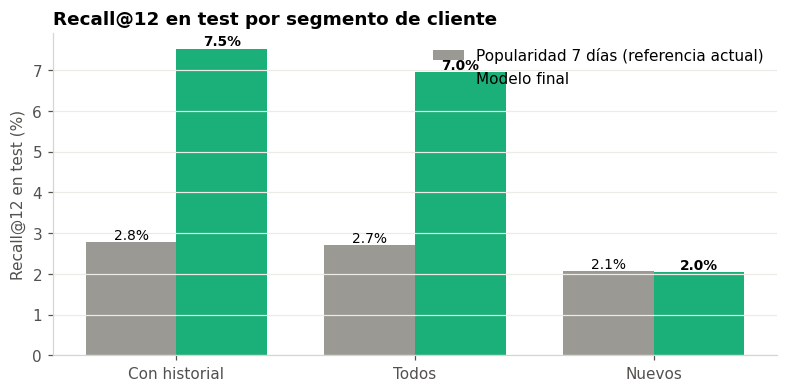

,Segmento,Clientes,Diferencia Recall@12 (puntos),IC 95% inferior,IC 95% superior,Conclusión
0,Con historial,3725,4.75,3.89,5.48,Mejora significativa
1,Nuevos,437,-0.03,-0.09,0.00,Sin diferencia significativa


In [15]:
resultados_ic = []
for g in ["Con historial", "Nuevos"]:
    comp = segmentos[g]
    dif = (detalle_por_cliente(comp, final.recomendar)[0]["recall"].to_numpy()
           - detalle_por_cliente(comp, base_orig.recomendar)[0]["recall"].to_numpy())
    media, bajo, alto = bootstrap(dif)
    resultados_ic.append({"Segmento": g, "Clientes": len(comp), "Diferencia Recall@12 (puntos)": round(media * 100, 2),
                          "IC 95% inferior": round(bajo * 100, 2), "IC 95% superior": round(alto * 100, 2),
                          "Conclusión": "Mejora significativa" if bajo > 0 else ("Empeora" if alto < 0 else "Sin diferencia significativa")})
ic = pd.DataFrame(resultados_ic)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
grupos = ["Con historial", "Todos", "Nuevos"]
x = np.arange(len(grupos)); w = 0.38
vb = [piv.loc[REF, g] for g in grupos]; vf = [piv.loc["Modelo final (por etapas)", g] for g in grupos]
ax.bar(x - w / 2, vb, w, color=GRIS, label="Popularidad 7 días (referencia actual)")
ax.bar(x + w / 2, vf, w, color=VERDE, label="Modelo final")
for xi, (a, b) in enumerate(zip(vb, vf)):
    ax.text(xi - w / 2, a, f"{a:.1f}%", ha="center", va="bottom", fontsize=9)
    ax.text(xi + w / 2, b, f"{b:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_xticks(x, grupos); ax.grid(axis="y"); ax.grid(axis="x", visible=False)
ax.set_ylabel("Recall@12 en test (%)"); ax.legend(loc="upper right")
ax.set_title("Recall@12 en test por segmento de cliente")
guardar(fig, "26_recall_final")
plt.show()
ic

### Interpretación

- **Clientes con historial (3.725, el 90% de los compradores de la semana):** el modelo final eleva el Recall@12 de 2,78% a 7,53%, unas 2,7 veces la referencia actual. La mejora es de +4,75 puntos, con un intervalo de confianza del 95% entre +3,89 y +5,48: no es atribuible al azar. El Hit Rate@12 pasa de 7,25% a 14,79%, es decir, el doble de clientes encuentra en su vitrina al menos una prenda que termina comprando.
- **Clientes nuevos (437):** el sistema les muestra el baseline y el resultado es equivalente a la referencia (2,04% frente a 2,07%, sin diferencia significativa). Sin historial no hay señal para personalizar; la mejora para este segmento requiere datos adicionales (ver próximos pasos).
- **Cobertura de catálogo:** la popularidad muestra las mismas 12 prendas a todos los clientes; el ranker recomienda 4.123 prendas distintas. Además de acertar más, da visibilidad a una parte mucho mayor del catálogo.
- **Consistencia con validación:** el orden de los modelos en test (ranker > co-compra > popularidad) es el mismo que en validación, lo que indica que la selección no se sobreajustó a la semana de validación.
- **Métricas de clasificación en test:** con el umbral calibrado en validación, la Accuracy (98,8%) queda por debajo de la del clasificador trivial (99,5%), pero el modelo detecta el 15,3% de las compras con una Precision del 8,3%, unas 17 veces la tasa base de compra (0,49%). ROC-AUC de 0,74.

---
# 9. Importancia de las variables

**Método:** importancia por permutación sobre el modelo seleccionado, en la semana de validación. Se desordena una variable por vez y se mide cuánto cae el PR-AUC: cuanto mayor la caída, más depende el modelo de esa variable. Para acotar el tiempo de cómputo se usan todas las compras y una muestra aleatoria de 50.000 pares sin compra.

**Por qué por permutación:** se aplica igual a la regresión logística y al Gradient Boosting, y mide el efecto sobre el desempeño en datos no usados para entrenar.

Tiempo: 15 s
Variables más influyentes: El cliente ya compró la prenda; Puntaje de co-compra; Días desde su última compra


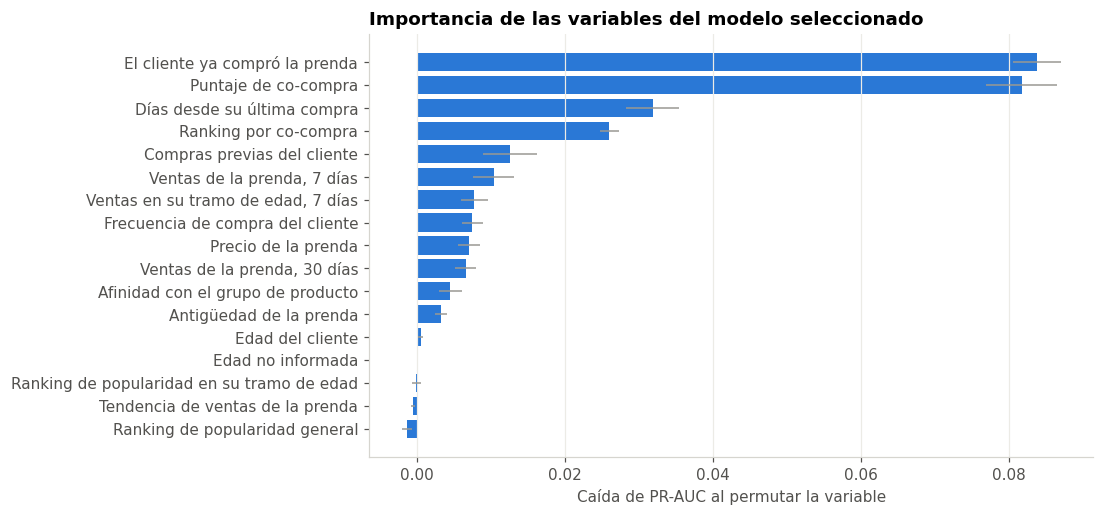

,Variable,Columna,Caída de PR-AUC,Desvío
0,El cliente ya compró la prenda,ya_lo_compro,0.0838,0.0032
1,Puntaje de co-compra,puntaje_cocompra,0.0818,0.0048
2,Días desde su última compra,dias_desde_ultima,0.0319,0.0036
3,Ranking por co-compra,rank_cocompra,0.0260,0.0012
4,Compras previas del cliente,n_compras,0.0126,0.0036
5,"Ventas de la prenda, 7 días",ventas_7d,0.0104,0.0027
6,"Ventas en su tramo de edad, 7 días",ventas_tramo_7d,0.0078,0.0019
7,Frecuencia de compra del cliente,compras_por_dia_activo,0.0075,0.0014
8,Precio de la prenda,precio_articulo,0.0070,0.0015
9,"Ventas de la prenda, 30 días",ventas_30d,0.0066,0.0014


In [16]:
NOMBRES = {"rank_pop": "Ranking de popularidad general", "rank_edad": "Ranking de popularidad en su tramo de edad",
           "rank_cocompra": "Ranking por co-compra", "puntaje_cocompra": "Puntaje de co-compra",
           "ya_lo_compro": "El cliente ya compró la prenda", "ventas_7d": "Ventas de la prenda, 7 días",
           "ventas_30d": "Ventas de la prenda, 30 días", "tendencia": "Tendencia de ventas de la prenda",
           "dias_desde_primera_venta": "Antigüedad de la prenda", "precio_articulo": "Precio de la prenda",
           "ventas_tramo_7d": "Ventas en su tramo de edad, 7 días", "afinidad_grupo": "Afinidad con el grupo de producto",
           "age": "Edad del cliente", "edad_faltante": "Edad no informada", "n_compras": "Compras previas del cliente",
           "dias_desde_ultima": "Días desde su última compra", "compras_por_dia_activo": "Frecuencia de compra del cliente"}
rng = np.random.default_rng(42)
pos = np.flatnonzero(y_val == 1)
neg = rng.choice(np.flatnonzero(y_val == 0), size=min(50_000, int((y_val == 0).sum())), replace=False)
idx = np.concatenate([pos, neg])
t0 = time.time()
perm = permutation_importance(clf_mejor, tabla_val.loc[idx, COLS], y_val[idx], scoring="average_precision",
                              n_repeats=5, random_state=42, n_jobs=1)
importancia = (pd.DataFrame({"Variable": [NOMBRES.get(c, c) for c in COLS], "Columna": COLS,
                             "Caída de PR-AUC": perm.importances_mean, "Desvío": perm.importances_std})
               .sort_values("Caída de PR-AUC", ascending=False).reset_index(drop=True))
print(f"Tiempo: {time.time() - t0:,.0f} s")
print("Variables más influyentes: " + "; ".join(importancia["Variable"].head(3)))

fig, ax = plt.subplots(figsize=(8.5, 5))
d = importancia.iloc[::-1]
ax.barh(d["Variable"], d["Caída de PR-AUC"], xerr=d["Desvío"], color=AZUL, error_kw={"ecolor": GRIS, "lw": 1})
ax.set_xlabel("Caída de PR-AUC al permutar la variable")
ax.set_title("Importancia de las variables del modelo seleccionado")
guardar(fig, "27_importancia_variables")
plt.show()
importancia.round(4)

### Interpretación

- **El comportamiento previo del cliente con la prenda es la señal más fuerte.** Que el cliente ya haya comprado la prenda (recompra) y el puntaje de co-compra son, por amplio margen, las dos variables más importantes: permutarlas reduce el PR-AUC en más de 0,08 cada una, más del doble que la tercera variable.
- **La recencia del cliente es la tercera señal:** quien compró hace pocos días tiene más probabilidad de volver a comprar en la semana.
- **La popularidad aporta poco una vez que se conoce al cliente.** Las ventas recientes de la prenda suman información, pero los rankings de popularidad general y por tramo de edad, la tendencia y la edad del cliente tienen importancia nula o levemente negativa. Esto es coherente con el notebook 03: la edad sola no supera a la popularidad y no agrega señal cuando hay historial.
- **Implicancia:** estas variables son candidatas a eliminarse en el próximo sprint para simplificar el modelo sin pérdida de desempeño. Para el negocio, la importancia de la recompra respalda acciones concretas como recordatorios de compra de otro color o talle.

---
# 10. Ejemplos de recomendaciones

Para verificar que las recomendaciones son coherentes, se muestran dos clientes con historial (sus últimas compras y las 12 prendas recomendadas, indicando cuáles compró en la semana de test) y un cliente nuevo.

In [17]:
info = art.set_index("article_id")
cols_info = [c for c in ["product_type_name", "colour_group_name", "index_group_name"] if c in info.columns]
etiquetas_info = {"product_type_name": "Tipo de prenda", "colour_group_name": "Color", "index_group_name": "Línea"}

def describir(articulos, compradas=None):
    filas = []
    for i, a in enumerate(articulos, 1):
        fila = {"Posición": i, "Artículo": a}
        fila.update({etiquetas_info[c]: info.at[a, c] if a in info.index else "-" for c in cols_info})
        if compradas is not None:
            fila["Comprada en test"] = "Sí" if a in compradas else "No"
        filas.append(fila)
    return pd.DataFrame(filas).set_index("Posición")

hist = segmentos["Con historial"]
aciertos = {c: len(a & set(final.recomendar(c))) for c, a in hist.items()}
ejemplos = sorted([c for c in aciertos if aciertos[c] > 0], key=lambda c: (-aciertos[c], str(c)))[:2]
for c in ejemplos:
    previas = train[train["customer_id"] == c].sort_values("t_dat", ascending=False)["article_id"].drop_duplicates().head(5).tolist()
    print(f"Cliente {str(c)[:10]}…  |  últimas compras antes del 16/09:")
    display(describir(previas))
    print(f"Recomendación del modelo final ({aciertos[c]} de 12 compradas en la semana de test):")
    display(describir(final.recomendar(c), hist[c]))

Cliente 5ea6959aa4…  |  últimas compras antes del 16/09:


,Artículo,Tipo de prenda,Color,Línea
Posición,,,,
1,0737221011,Underwear bottom,Light Pink,Ladieswear
2,0736923009,Bra,White,Ladieswear
3,0817401004,Shorts,Black,Ladieswear
4,0736923011,Bra,Light Pink,Ladieswear
5,0737221009,Underwear bottom,White,Ladieswear


Recomendación del modelo final (4 de 12 compradas en la semana de test):


,Artículo,Tipo de prenda,Color,Línea,Comprada en test
Posición,,,,,
1,0736923011,Bra,Light Pink,Ladieswear,Sí
2,0736923009,Bra,White,Ladieswear,Sí
3,0737221009,Underwear bottom,White,Ladieswear,Sí
4,0817401004,Shorts,Black,Ladieswear,No
5,0737221011,Underwear bottom,Light Pink,Ladieswear,Sí
6,0736923003,Bra,Black,Ladieswear,No
7,0757971001,Underwear bottom,Black,Ladieswear,No
8,0631536028,Socks,Beige,Ladieswear,No
9,0884319005,Blouse,Light Beige,Ladieswear,No


Cliente 5edf6be61a…  |  últimas compras antes del 16/09:


,Artículo,Tipo de prenda,Color,Línea
Posición,,,,
1,0906352001,Sweater,Off White,Ladieswear
2,0909370001,Dress,Off White,Ladieswear
3,0923569002,Top,Beige,Ladieswear
4,0869379007,Skirt,Dark Beige,Divided
5,0923128001,Dress,Off White,Ladieswear


Recomendación del modelo final (4 de 12 compradas en la semana de test):


,Artículo,Tipo de prenda,Color,Línea,Comprada en test
Posición,,,,,
1,0906352001,Sweater,Off White,Ladieswear,Sí
2,0909370001,Dress,Off White,Ladieswear,Sí
3,0923569002,Top,Beige,Ladieswear,Sí
4,0923128001,Dress,Off White,Ladieswear,No
5,0869379007,Skirt,Dark Beige,Divided,Sí
6,0914805002,Top,Black,Ladieswear,No
7,0909371001,Dress,Black,Ladieswear,No
8,0865799006,Trousers,Light Beige,Ladieswear,No
9,0874704002,Sweater,Light Beige,Ladieswear,No


In [18]:
nuevos = segmentos["Nuevos"]
c_nuevo = sorted(nuevos, key=str)[0]
print(f"Cliente nuevo {str(c_nuevo)[:10]}…  |  sin compras previas: recibe el baseline seleccionado")
describir(final.recomendar(c_nuevo), nuevos[c_nuevo])

Cliente nuevo 009d1f0141…  |  sin compras previas: recibe el baseline seleccionado


,Artículo,Tipo de prenda,Color,Línea,Comprada en test
Posición,,,,,
1,0448509014,Trousers,Blue,Divided,No
2,0865799006,Trousers,Light Beige,Ladieswear,No
3,0809238001,Sweater,Black,Divided,No
4,0751471001,Trousers,Black,Ladieswear,No
5,0924243001,Sweater,Beige,Ladieswear,No
6,0923758001,Unknown,White,Ladieswear,No
7,0896169005,Cardigan,Light Purple,Ladieswear,No
8,0918522001,Sweater,Off White,Ladieswear,No
9,0809238005,Sweater,Dark Grey,Divided,No


### Interpretación

- **Las recomendaciones son coherentes con el perfil de cada cliente.** La primera clienta compraba ropa interior y el modelo prioriza esa categoría, en los mismos colores; la segunda compraba vestidos, sweaters y tops en tonos claros, y el modelo completa la lista con prendas similares en esa gama.
- **Los aciertos provienen principalmente de la recompra:** en ambos casos, las prendas compradas en la semana de test son prendas que la clienta ya había comprado y que el modelo ubicó en las primeras posiciones. Es consistente con la importancia de variables de la sección 9.
- **El resto de la lista agrega variedad dentro del estilo del cliente** (mismo tipo de prenda o línea, otros colores), lo que explica la mayor cobertura de catálogo.
- **El cliente nuevo recibe la vitrina general** y, en este caso, no compró ninguna de las 12 prendas. Muestra el límite del sistema para clientes sin historial: la recomendación es razonable, pero no personalizada.

---
# 11. Justificación del modelo elegido

### Decisiones del proceso

| # | Decisión | Alternativas consideradas | Justificación | Evidencia |
|---|---|---|---|---|
| 1 | Muestra p10 (10% de los clientes) | Dataset completo; muestra del 5% | El dataset completo excede la memoria disponible; p10 conserva la distribución y duplica la señal de p5 | EDA y controles de integridad |
| 2 | Conservar duplicados (12,8%) | Eliminarlos | No se puede distinguir un error de la compra de varias unidades; eliminarlos subestimaría la demanda | Notebook 04 |
| 3 | No imputar la edad (1,1% faltante) | Media o mediana | Imputar asignaría preferencias de otro tramo; se agrega un indicador de edad faltante | Notebook 04 |
| 4 | Partición temporal | Partición aleatoria | La aleatoria filtra información futura | Sección 1 |
| 5 | Recall@12 como métrica de decisión | Accuracy; MAP@12 | Se vincula con la conversión; la Accuracy no discrimina con clases desbalanceadas | Secciones 2 y 4 |
| 6 | Baseline optimizado en 4 semanas | Popularidad de 7 días fija; elegir con una semana | Comparación más exigente y estable | Sección 3 |
| 7 | Regresión logística como modelo base | Empezar con modelos complejos | Simple e interpretable: fija el piso que un modelo complejo debe superar | Sección 4 |
| 8 | Búsqueda de hiperparámetros con `class_weight` | Valores por defecto | Las compras son el 0,5% de los pares | Sección 5 |
| 9 | Elegir el modelo complejo solo con mejora significativa | Elegir el de mayor promedio | Evita sumar complejidad por diferencias atribuibles al azar | Sección 6 |
| 10 | Sistema por etapas | Un único modelo para todos | Sin historial no hay personalización posible; el ranker solo se aplica donde aporta | Secciones 8 y 10; notebook 05 |
| 11 | Intervalos de confianza por bootstrap | Comparar promedios | Distingue mejoras reales de variaciones aleatorias | Secciones 6 y 8 |

### Alternativas descartadas

| Alternativa | Por qué se descartó |
|---|---|
| Popularidad como única estrategia | Recall@12 cerca de tres veces menor en clientes con historial; muestra las mismas 12 prendas a todos |
| Co-compra como modelo final | Buen desempeño, pero inferior al ranker, que la incorpora como candidata y como variable |
| Clasificador elegido por Accuracy | Seleccionaría modelos que no detectan compras |
| Configuraciones de Gradient Boosting de mayor tamaño | Menor Recall@12 en validación, señal de sobreajuste |
| Personalizar a clientes nuevos con el ranker | Sin historial, las variables del cliente quedan vacías y no se observa mejora frente a la popularidad |

---
# 12. Limitaciones, conclusiones y próximos pasos

### Limitaciones y compromisos

- **Techo de candidatas:** el ranker solo puede recomendar prendas que estén entre sus ~40 candidatas, que contienen alrededor del 12% de las compras. El Recall@12 está acotado por ese límite.
- **Clientes nuevos:** representan cerca del 10% de los compradores semanales y no reciben recomendaciones personalizadas.
- **Evaluación offline:** se mide si el cliente compró lo recomendado, no si la recomendación causó la compra. El impacto real en conversión requiere una prueba A/B.
- **Muestra y período:** los resultados corresponden a una muestra del 10% y a una semana de test de septiembre; la estacionalidad puede cambiar la magnitud de la mejora.
- **Complejidad frente a interpretabilidad:** si se usa Gradient Boosting, se gana desempeño a cambio de un modelo menos transparente que la regresión logística; la importancia por permutación compensa parcialmente esa pérdida.

### Conclusiones

1. La personalización aporta valor medible: para los clientes con historial, el modelo final supera con claridad a la referencia actual y la mejora es estadísticamente significativa.
2. Las señales más útiles son la recencia y la recompra.
3. La Accuracy no es una métrica adecuada para este problema; Recall@12, complementado con MAP@12 y PR-AUC, refleja mejor el valor para el negocio.
4. El sistema por etapas es la opción recomendada: popularidad reciente para clientes nuevos y ranker desde la primera compra.

### Próximos pasos (Sprint 2)

1. Ampliar la generación de candidatas (prendas nuevas, similares por atributos) para elevar el techo del Recall.
2. Validación con varias semanas también para los hiperparámetros.
3. Recolectar preferencias mínimas en el registro para personalizar a clientes nuevos.
4. Aplicación de demostración en Streamlit, registro de experimentos en MLflow y diseño de una prueba A/B.

---
# 13. Persistencia del modelo y exportación de resultados

Se guardan en `models/` los artefactos necesarios para generar recomendaciones sin reentrenar:

| Archivo | Contenido |
|---|---|
| `ranker_clasificador.joblib` | Clasificador entrenado del modelo seleccionado |
| `configuracion_modelo.json` | Algoritmo, hiperparámetros, variables, umbral, baseline y su top 12, fecha de corte y métricas de test |
| `recomendaciones_semana_test.csv` | Las 12 recomendaciones de cada cliente de la semana de test, en orden |

Al final se verifica que el modelo cargado desde disco produce exactamente las mismas predicciones.

In [19]:
joblib.dump(ranker.clf, f"{MODEL_DIR}/ranker_clasificador.joblib")
config = {
    "fecha_corte": str(CORTE_TEST.date()),
    "ranker": {"algoritmo": nombre_alg[MEJOR_CFG["algoritmo"]],
               "hiperparametros": {k: v for k, v in MEJOR_CFG.items() if k != "algoritmo"},
               "variables": list(COLS), "umbral_mejor_f1": round(U_MEJOR, 5)},
    "baseline_optimizado": {"nombre": BASELINE_OPT.nombre, "top12": [int(a) for a in base_test.top]},
    "cocompra": {"dias_pares": COCOMPRA.dias_pares, "peso_recompra": COCOMPRA.peso_recompra},
    "metricas_test_recall_at_12": {g: round(float(piv.loc["Modelo final (por etapas)", g]) / 100, 5) for g in ["Todos", "Con historial", "Nuevos"]},
}
with open(f"{MODEL_DIR}/configuracion_modelo.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)
recs = pd.DataFrame([{"customer_id": c, "posicion": i + 1, "article_id": int(a)}
                     for c in compras_test for i, a in enumerate(final.recomendar(c))])
recs.to_csv(f"{MODEL_DIR}/recomendaciones_semana_test.csv", index=False, encoding="utf-8")
cargado = joblib.load(f"{MODEL_DIR}/ranker_clasificador.joblib")
ok = np.allclose(cargado.predict_proba(ranker.tabla_prediccion[COLS].head(100))[:, 1], prob_test[:100])
print(f"Artefactos guardados en models/: {len(recs):,} recomendaciones para {recs['customer_id'].nunique():,} clientes")
print("Verificación de carga: " + ("predicciones idénticas" if ok else "las predicciones difieren, revisar"))

Artefactos guardados en models/: 49,944 recomendaciones para 4,162 clientes
Verificación de carga: predicciones idénticas


In [20]:
tabla_bonita(val_base.drop(columns="_obj")).to_csv(f"{OUT_DIR}/baseline_optimizado_validacion.csv", index=False, encoding="utf-8-sig")
busqueda.drop(columns="_cfg").round(5).to_csv(f"{OUT_DIR}/busqueda_hiperparametros.csv", index=False, encoding="utf-8-sig")
tabla_bonita(res_test).to_csv(f"{OUT_DIR}/resultados_test_optimizado.csv", index=False, encoding="utf-8-sig")
clf_test.round(5).to_csv(f"{OUT_DIR}/metricas_clasificacion_test.csv", index=False, encoding="utf-8-sig")
ic.to_csv(f"{OUT_DIR}/intervalos_confianza_test.csv", index=False, encoding="utf-8-sig")
importancia.round(5).to_csv(f"{OUT_DIR}/importancia_variables.csv", index=False, encoding="utf-8-sig")
print("Resultados exportados a reports/ (6 archivos CSV)")

Resultados exportados a reports/ (6 archivos CSV)
